<a href="https://colab.research.google.com/github/kjmobile/lb2/blob/main/6_Decision_Tree_Late_Flights_all.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6. Decision Tree: Which Flights Will Arrive Late?

An airline's operations center watches hundreds of flights at once. Which ones will arrive late? A **decision
tree** answers with a short list of yes/no questions, such as *"Is the incoming plane more than 25 minutes late?"*.
People can read the answer, which is the tree's biggest strength.

- **Predict (y):** `late` (1 = arrived 15 or more minutes late, 0 = on time)
- **From (X):** `month`, `dep_hour`, `distance`, `inbound_delay`, `turn_minutes`

Slides: W3.1, decision tree (information gain, entropy vs. Gini impurity).

> **Data.** 2,000 U.S. domestic flights from 2024, picked at random from the on-time records of the U.S. Bureau of
> Transportation Statistics (BTS), read straight from the course GitHub repository. Source: BTS Marketing Carrier
> On-Time Performance, 2024 (public data).

> **Full version.** This notebook includes the code that draws every figure. The `_simple` version leaves that code out and shows the same figures as pictures.

## 1. Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

flights = pd.read_csv('https://raw.githubusercontent.com/kjmobile/lb2/main/data/flights_late_2024.csv')
flights.head()

,month,dep_hour,distance,inbound_delay,turn_minutes,late
0,7,17,195,4,35,0
1,1,14,239,1,50,0
2,4,18,986,-7,84,0
3,4,8,224,5,30,0
4,8,16,327,36,45,1


| Column | Meaning |
|---|---|
| `month` | 1 = January ... 12 = December |
| `dep_hour` | scheduled departure hour (6 = 6 a.m., 18 = 6 p.m.) |
| `distance` | flight distance in miles |
| `inbound_delay` | how late the **incoming plane** arrived, in minutes (negative = early). An airplane flies several legs a day, so the plane for this flight usually flies in from another airport first |
| `turn_minutes` | scheduled minutes between the incoming plane's arrival and this flight's departure |
| `late` | 1 = arrived 15 or more minutes late (the official definition of a late flight), 0 = on time |

In [2]:
print(flights.shape)
print('share of late flights:', round(flights['late'].mean(), 3))

(2000, 6)
share of late flights: 0.208


## 2. Look Before You Model

Compare flights whose incoming plane was on time with flights whose plane came in 15+ minutes late.

In [3]:
# False = incoming plane less than 15 minutes late, True = 15 or more
flights.groupby(flights['inbound_delay'] >= 15)['late'].mean().round(3)

inbound_delay
False    0.115
True     0.650
Name: late, dtype: float64

When the plane comes in late, most flights leave late and arrive late too. The airline calls this a
**delay that propagates** through the day.

## 3. Split the Data

We keep 20% of the flights aside as the **test set**. **Accuracy** is the share of test flights labeled correctly.
The **baseline** is the accuracy of always guessing "on time", the larger group.

In [4]:
X = flights.drop(columns='late')     # five inputs
y = flights['late']
train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=320, stratify=y)

print('train:', train_X.shape, ' test:', test_X.shape)
print('baseline (always guess "on time"):', round(1 - test_y.mean(), 3))

train: (1600, 5)  test: (400, 5)
baseline (always guess "on time"): 0.792


## 4. A Tree That Grows Until It Stops

By default the tree keeps asking questions until every training flight is in a group of its own kind.

In [5]:
full_tree = DecisionTreeClassifier(random_state=320)
full_tree.fit(train_X, train_y)

print('train accuracy:', round(full_tree.score(train_X, train_y), 3))
print('test accuracy: ', round(full_tree.score(test_X, test_y), 3))
print('depth:', full_tree.get_depth(), ' leaves (final groups):', full_tree.get_n_leaves())

train accuracy: 1.0
test accuracy:  0.785
depth: 24  leaves (final groups): 245


Perfect on the training flights, but on new flights it does **worse than always guessing "on time"**. The tree
memorized the training flights, noise included. This is **overfitting**.

## 5. Prune the Tree

Limit the tree to three rounds of questions with `max_depth=3`.

In [6]:
tree = DecisionTreeClassifier(max_depth=3, random_state=320)
tree.fit(train_X, train_y)

print('train accuracy:', round(tree.score(train_X, train_y), 3))
print('test accuracy: ', round(tree.score(test_X, test_y), 3))

train accuracy: 0.875
test accuracy:  0.863


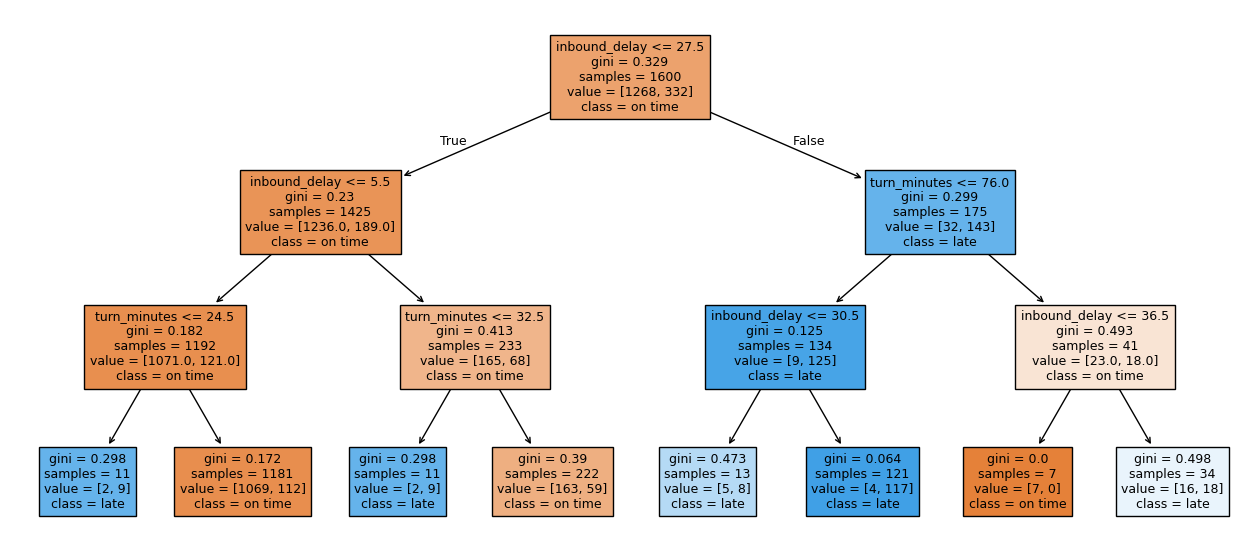

In [7]:
# Figure 1
plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=list(X.columns), class_names=['on time', 'late'], filled=True, fontsize=9)
plt.show()

The same tree as text:

In [8]:
print(export_text(tree, feature_names=list(X.columns)))

|--- inbound_delay <= 27.50
|   |--- inbound_delay <= 5.50
|   |   |--- turn_minutes <= 24.50
|   |   |   |--- class: 1
|   |   |--- turn_minutes >  24.50
|   |   |   |--- class: 0
|   |--- inbound_delay >  5.50
|   |   |--- turn_minutes <= 32.50
|   |   |   |--- class: 1
|   |   |--- turn_minutes >  32.50
|   |   |   |--- class: 0
|--- inbound_delay >  27.50
|   |--- turn_minutes <= 76.00
|   |   |--- inbound_delay <= 30.50
|   |   |   |--- class: 1
|   |   |--- inbound_delay >  30.50
|   |   |   |--- class: 1
|   |--- turn_minutes >  76.00
|   |   |--- inbound_delay <= 36.50
|   |   |   |--- class: 0
|   |   |--- inbound_delay >  36.50
|   |   |   |--- class: 1



**Read the tree.** The first question is about the incoming plane: more than 27.5 minutes late? If so, the flight is
predicted late unless the schedule left a long turn (more than 76 minutes) and the plane was not too late.
If the plane is on time, the flight is late only when the turn is extremely short. Month, departure hour and
distance are never asked: three questions about the incoming plane and the turn are enough.

## 6. How the Tree Chose Its First Question

At each step, the tree picks the question that makes the groups **purest**. scikit-learn measures impurity with
**Gini impurity** by default:

$$\text{Gini}(D) = 1 - \sum_i p_i^2$$

For two classes it is 0 when a group is all one class and 0.5 when it is half and half. The **information gain**
of a question is the parent's impurity minus the weighted impurity of the two groups it creates:

$$IG = I(D_p) - \frac{N_{left}}{N_p} I(D_{left}) - \frac{N_{right}}{N_p} I(D_{right})$$

In [9]:
def gini(labels):
    p = labels.mean()                 # share of late flights in the group
    return 1 - p ** 2 - (1 - p) ** 2

left = train_y[train_X['inbound_delay'] <= 27.5]     # the tree's first question
right = train_y[train_X['inbound_delay'] > 27.5]

print('Gini before the split:', round(gini(train_y), 3))
print('Gini, left group: ', round(gini(left), 3), ' flights:', len(left))
print('Gini, right group:', round(gini(right), 3), ' flights:', len(right))

after = len(left) / len(train_y) * gini(left) + len(right) / len(train_y) * gini(right)
print('information gain:', round(gini(train_y) - after, 3))

Gini before the split: 0.329
Gini, left group:  0.23  flights: 1425
Gini, right group: 0.299  flights: 175
information gain: 0.091


These are the `gini` and `samples` numbers in the top three boxes of the tree picture. The tree tried every input
and every cut-off, and this question gave the largest gain.

**Entropy** is the other common impurity measure, $-\sum_i p_i \log_2 p_i$ (0 to 1 for two classes). It usually
picks the same questions; Gini is the default because it is cheaper to compute.

## 7. Which Inputs Mattered?

**Feature importance** is each input's share of the total impurity reduction in the tree.

In [10]:
pd.Series(tree.feature_importances_, index=X.columns).round(3)

month            0.000
dep_hour         0.000
distance         0.000
inbound_delay    0.834
turn_minutes     0.166
dtype: float64

## 8. How Deep Should the Tree Be?

Try depths 1 to 12 and compare training and test accuracy.

In [11]:
rows = []
for depth in range(1, 13):
    t = DecisionTreeClassifier(max_depth=depth, random_state=320)
    t.fit(train_X, train_y)
    rows.append({'max_depth': depth, 'train': t.score(train_X, train_y), 'test': t.score(test_X, test_y)})

depth_scores = pd.DataFrame(rows).round(3)
depth_scores

,max_depth,train,test
0,1,0.862,0.862
1,2,0.865,0.852
2,3,0.875,0.862
3,4,0.880,0.858
4,5,0.886,0.862
5,6,0.893,0.865
6,7,0.904,0.858
7,8,0.912,0.850
8,9,0.921,0.838
9,10,0.931,0.820


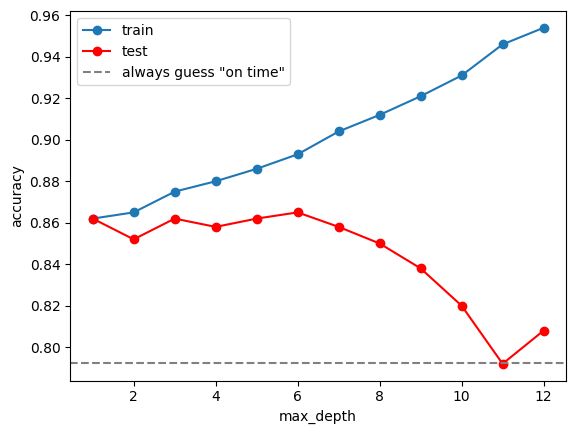

In [12]:
# Figure 2
plt.plot(depth_scores['max_depth'], depth_scores['train'], marker='o', label='train')
plt.plot(depth_scores['max_depth'], depth_scores['test'], marker='o', color='red', label='test')
plt.axhline(1 - test_y.mean(), color='gray', linestyle='--', label='always guess "on time"')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.legend()
plt.show()

Training accuracy keeps rising with depth; test accuracy stops improving after a few levels and then falls.
A deeper tree learns more about the training flights and less about flights in general.

One problem: we just used the **test set** to choose the depth. Then the test set is no longer an unseen
"final exam". Notebook 7 fixes this with a validation set and cross-validation.

### Your turn

An evening flight in July (800 miles) is scheduled with a **50-minute** turn, and its incoming plane is
**40 minutes** late. Ask the pruned `tree` for the probability that it arrives late, then try a **120-minute** turn.

1. In the cell below, fill in the blanks (`___`) and run it.
2. Then finish this sentence:
   *With a 50-minute turn the tree gives a ___ chance of arriving late; with a 120-minute turn, ___.*

<details><summary>Show answer</summary>

```python
flight = pd.DataFrame({'month': [7], 'dep_hour': [18], 'distance': [800],
                       'inbound_delay': [40], 'turn_minutes': [50]})
print('50-minute turn: ', tree.predict_proba(flight)[0, 1].round(3))

flight['turn_minutes'] = 120
print('120-minute turn:', tree.predict_proba(flight)[0, 1].round(3))
```

*With a 50-minute turn the tree gives a **0.967** chance of arriving late; with a 120-minute turn, **0.529**. A longer turn absorbs part of the incoming delay.*
</details>

In [ ]:
flight = pd.DataFrame({'month': [7], 'dep_hour': [18], 'distance': [800],
                       'inbound_delay': [___], 'turn_minutes': [50]})
print('50-minute turn: ', tree.___(flight)[0, 1].round(3))

flight['turn_minutes'] = 120
print('120-minute turn:', tree.predict_proba(flight)[0, 1].round(3))

## 9. Summary

| Step | What we found |
|---|---|
| Baseline | Always guessing "on time" is right 79% of the time |
| Full tree | 100% on training flights, but worse than the baseline on test flights (overfitting) |
| Pruned tree (depth 3) | About 86% on test flights, and readable as three questions |
| First question | Is the incoming plane more than 27.5 minutes late? It gave the largest information gain |
| Important inputs | The incoming plane's delay, then the scheduled turn time |

---
# Challenge

1. Fit the tree with `criterion='entropy'` instead of the default Gini. Does the first question change? Does the
   test accuracy change?
2. Instead of `max_depth`, try `min_samples_leaf=50` (every final group must hold at least 50 training flights).
   How deep does the tree grow, and how accurate is it?
3. An operations manager asks: "Why does the tree never ask about the month or the hour?" Answer in two sentences.

In [14]:
# Your answer